### 1. Data Loading and Cleaning

In [11]:
import pandas as pd

# Load dataset from Excel file
df = pd.read_excel('datathon-dataset-2026.xlsx', sheet_name='data')

,student_id,entry_year,credit_hrs,app_dt,app_mo,app_yr,app_fee,acceptance_fee,hs_gpa,act_cmpst,...,hs_only_math,hs_only_sci,rotc_interest,miles_from_campus,veteran,age,stem_major,urm,sex,college
0,145382.0,2022,0.0,13.0,nov,2021,Deferred,NaN,2.15,11.0,...,8.0,8.0,0,855.0,0,20.0,0,1,M,Public Health and Translational Science
1,89694.0,2022,0.0,27.0,dec,2021,Deferred,NaN,2.14,11.0,...,NaN,4.0,0,307.0,0,18.0,0,1,M,Public Health and Translational Science
2,112761.0,2022,0.0,27.0,nov,2021,Deferred,NaN,2.67,11.0,...,NaN,NaN,0,534.0,0,19.0,1,1,F,Public Health and Translational Science
3,61545.0,2022,0.0,11.0,oct,2021,Deferred,NaN,2.84,11.0,...,8.0,7.0,0,29.0,0,18.0,0,0,M,Liberal Arts and Sciences
4,113888.0,2022,0.0,9.0,aug,2021,Paid,NaN,2.22,12.0,...,NaN,NaN,0,226.0,0,18.0,0,1,M,"Business, Finance and Industry"


In [21]:
# Find number of rows and columns in the dataset
nrow, ncol = df.shape
print(f"The dataset has {nrow} rows and {ncol} columns.")

The dataset has 69557 rows and 67 columns.


In [12]:
# Display the first few rows of the dataset
display(df.head())

,student_id,entry_year,credit_hrs,app_dt,app_mo,app_yr,app_fee,acceptance_fee,hs_gpa,act_cmpst,...,hs_only_math,hs_only_sci,rotc_interest,miles_from_campus,veteran,age,stem_major,urm,sex,college
0,145382.0,2022,0.0,13.0,nov,2021,Deferred,NaN,2.15,11.0,...,8.0,8.0,0,855.0,0,20.0,0,1,M,Public Health and Translational Science
1,89694.0,2022,0.0,27.0,dec,2021,Deferred,NaN,2.14,11.0,...,NaN,4.0,0,307.0,0,18.0,0,1,M,Public Health and Translational Science
2,112761.0,2022,0.0,27.0,nov,2021,Deferred,NaN,2.67,11.0,...,NaN,NaN,0,534.0,0,19.0,1,1,F,Public Health and Translational Science
3,61545.0,2022,0.0,11.0,oct,2021,Deferred,NaN,2.84,11.0,...,8.0,7.0,0,29.0,0,18.0,0,0,M,Liberal Arts and Sciences
4,113888.0,2022,0.0,9.0,aug,2021,Paid,NaN,2.22,12.0,...,NaN,NaN,0,226.0,0,18.0,0,1,M,"Business, Finance and Industry"


In [ ]:
# Find columns with most null values in the dataset; exclude target variable 'enrolled' from the null value check
df.isnull().sum().drop('enrolled', errors='ignore').sort_values(ascending=False).head(20)

sat_math            61755
sat_comb            61755
sat_vrbl            61755
deposit_dt          44085
deposit_mo          43932
acceptance_fee      43587
deposit_yr          43326
visit_mo            37153
visit_yr            37153
visit_dt            37153
act_engl            18493
act_math            18492
act_cmpst           18396
hs_only_sci         18000
hs_flang            17075
hs_sci              16955
hs_only_math        11689
hs_ss               11307
hs_math             10606
first_contact_dt     2509
dtype: int64

It seems as if there is almost no information information about SAT scores, and not a lot of information about dates for admission offer acceptances and campus visits. Comparatively to SAT scores, even though there is missing information about ACT scores, the amount present is significantly more than for SAT scores, which makes sense because students more commonly take the ACT as a standardized test over the SAT.

In [30]:
# Split the dataset into features (X) and target variable (y)
X = df.drop('enrolled', axis=1)
y = df['enrolled']

### 2. Feature Selection

In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder

# Categorical columns to be one-hot encoded
categorical_columns = X.select_dtypes(include=['object', 'category']).columns

# One-hot encode the categorical columns
encoder = OneHotEncoder(sparse_output=False, drop='first')
X_encoded = encoder.fit_transform(X[categorical_columns])

# Find out important features using Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_encoded, y)

feature_importance = rf.feature_importances_
feature_names = encoder.get_feature_names_out(categorical_columns)

# Create a DataFrame to display feature importance
importance_df = pd.DataFrame({'feature': feature_names, 'importance': feature_importance})
importance_df = importance_df.sort_values('importance', ascending=False)

display(importance_df.head(50))

C:\Users\manth\AppData\Local\Temp\ipykernel_10368\2823346844.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=['object', 'category']).columns


,feature,importance
16,acceptance_fee_nan,0.492206
14,acceptance_fee_Paid,0.302305
30,visit_mo_nan,0.034522
18,residency_Resident,0.020545
43,sex_M,0.011906
11,app_fee_Paid,0.008814
17,residency_Non-Contiguous,0.007311
46,college_Liberal Arts and Sciences,0.005876
25,visit_mo_Mar,0.005661
42,first_contact_mo_nan,0.004873


In [42]:
# Filter dataset such that only important features are retained; keep only features with importance greater than a threshold (e.g., 0.001)
X_filtered = X_encoded[:, importance_df[importance_df['importance'] > 0.001].index]

### 3. Model Training and Comparison

In [43]:
from sklearn.model_selection import train_test_split

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_filtered, y, test_size=0.2, random_state=42)

#### Logistic Regression

In [44]:
from sklearn.linear_model import LogisticRegression

# Train a logistic regression model
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

# Make predictions
y_pred_logreg = logreg.predict(X_test)

#### Lasso Regression

In [45]:
from sklearn.linear_model import Lasso

# Train a Lasso regression model
lasso = Lasso(alpha=0.01)
lasso.fit(X_train, y_train)

# Make predictions
y_pred_lasso = lasso.predict(X_test)

#### ElasticNet

In [46]:
from sklearn.linear_model import ElasticNet

# Train an Elastic Net regression model
elastic_net = ElasticNet(alpha=0.01, l1_ratio=0.5)
elastic_net.fit(X_train, y_train)

# Make predictions
y_pred_elastic_net = elastic_net.predict(X_test)

#### Ridge Regression

In [47]:
from sklearn.linear_model import Ridge

# Train a Ridge regression model
ridge = Ridge(alpha=0.01)
ridge.fit(X_train, y_train)

# Make predictions
y_pred_ridge = ridge.predict(X_test)

#### Random Forest Regression

In [48]:
from sklearn.ensemble import RandomForestRegressor

# Train a Random Forest regression model
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf.predict(X_test)

#### Gradient Boosting Regression

In [49]:
from sklearn.ensemble import GradientBoostingRegressor

# Train a Gradient Boosting regression model
gbr = GradientBoostingRegressor(n_estimators=100, random_state=42)
gbr.fit(X_train, y_train)

# Make predictions
y_pred_gbr = gbr.predict(X_test)

#### Model Comparison

In [62]:
# Compare the performance of different models using R-squared score,  F1 score, Accuracy, Precision, Recall, Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and Mean Absolute Error (MAE)
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

# Calculate metrics for each model
r2_logreg = r2_score(y_test, y_pred_logreg)
r2_lasso = r2_score(y_test, y_pred_lasso)
r2_elastic_net = r2_score(y_test, y_pred_elastic_net)
r2_ridge = r2_score(y_test, y_pred_ridge)
r2_rf = r2_score(y_test, y_pred_rf)
r2_gbr = r2_score(y_test, y_pred_gbr)

adj_r2_logreg = 1 - (1 - r2_logreg) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)
adj_r2_lasso = 1 - (1 - r2_lasso) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)
adj_r2_elastic_net = 1 - (1 - r2_elastic_net) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)
adj_r2_ridge = 1 - (1 - r2_ridge) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)
adj_r2_rf = 1 - (1 - r2_rf) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)
adj_r2_gbr = 1 - (1 - r2_gbr) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)

rmse_logreg = root_mean_squared_error(y_test, y_pred_logreg)
rmse_lasso = root_mean_squared_error(y_test, y_pred_lasso)
rmse_elastic_net = root_mean_squared_error(y_test, y_pred_elastic_net)
rmse_ridge = root_mean_squared_error(y_test, y_pred_ridge)
rmse_rf = root_mean_squared_error(y_test, y_pred_rf)
rmse_gbr = root_mean_squared_error(y_test, y_pred_gbr)

mae_logreg = mean_absolute_error(y_test, y_pred_logreg)
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
mae_elastic_net = mean_absolute_error(y_test, y_pred_elastic_net)
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mae_gbr = mean_absolute_error(y_test, y_pred_gbr)

# Create a DataFrame to display the metrics for each model
metrics_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Lasso Regression', 'Elastic Net Regression', 'Ridge Regression', 'Random Forest Regression', 'Gradient Boosting Regression'],
    'R-squared': [r2_logreg, r2_lasso, r2_elastic_net, r2_ridge, r2_rf, r2_gbr],
    'Adjusted R-squared': [adj_r2_logreg, adj_r2_lasso, adj_r2_elastic_net, adj_r2_ridge, adj_r2_rf, adj_r2_gbr],
    'RMSE': [rmse_logreg, rmse_lasso, rmse_elastic_net, rmse_ridge, rmse_rf, rmse_gbr],
    'MAE': [mae_logreg, mae_lasso, mae_elastic_net, mae_ridge, mae_rf, mae_gbr]
})

display(metrics_df)

,Model,R-squared,Adjusted R-squared,RMSE,MAE
0,Logistic Regression,0.802704,0.802050,0.207846,0.043200
1,Lasso Regression,0.821722,0.821131,0.197575,0.095102
2,Elastic Net Regression,0.821905,0.821314,0.197474,0.092244
3,Ridge Regression,0.825416,0.824836,0.195518,0.084551
4,Random Forest Regression,0.781966,0.781243,0.218497,0.078569
5,Gradient Boosting Regression,0.829207,0.828641,0.193383,0.075767


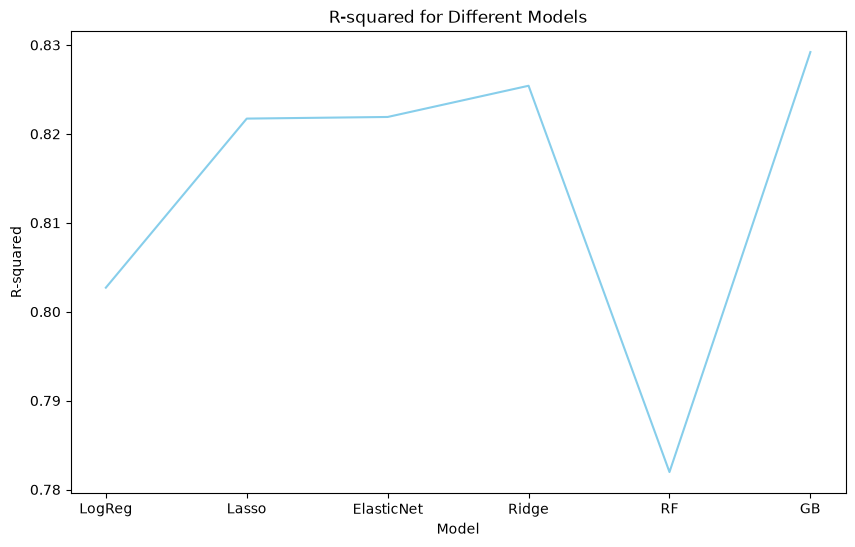

In [ ]:
# Plot the metrics for each model using a curve
import matplotlib.pyplot as plt

models_abb = ['LogReg', 'Lasso', 'ElasticNet', 'Ridge', 'RF', 'GB']

# Plot R-squared
plt.figure(figsize=(10, 6))
plt.plot(models_abb, metrics_df['R-squared'], color='skyblue')
plt.xlabel('Model')
plt.ylabel('R-squared')
plt.title('R-squared for Different Models')
plt.show()

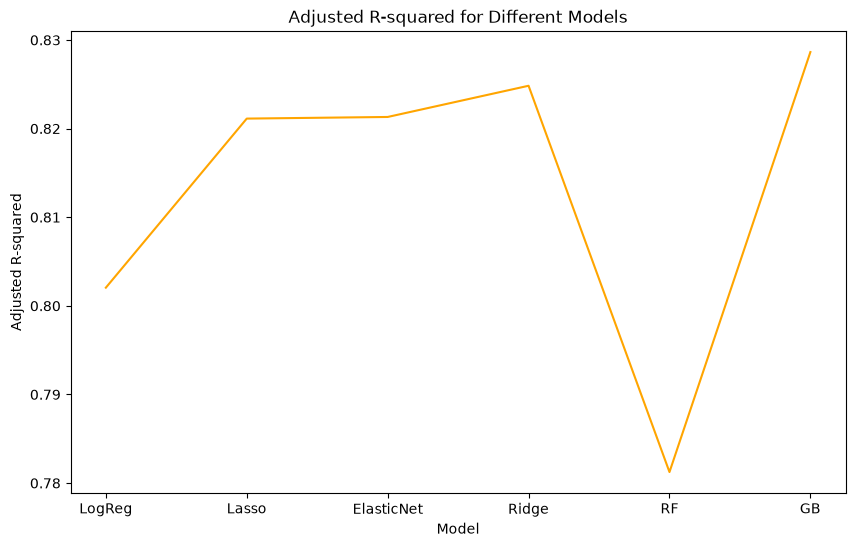

In [67]:
# Plot Adjusted R-squared
plt.figure(figsize=(10, 6))
plt.plot(models_abbr, metrics_df['Adjusted R-squared'], color='orange')
plt.xlabel('Model')
plt.ylabel('Adjusted R-squared')
plt.title('Adjusted R-squared for Different Models')
plt.show()

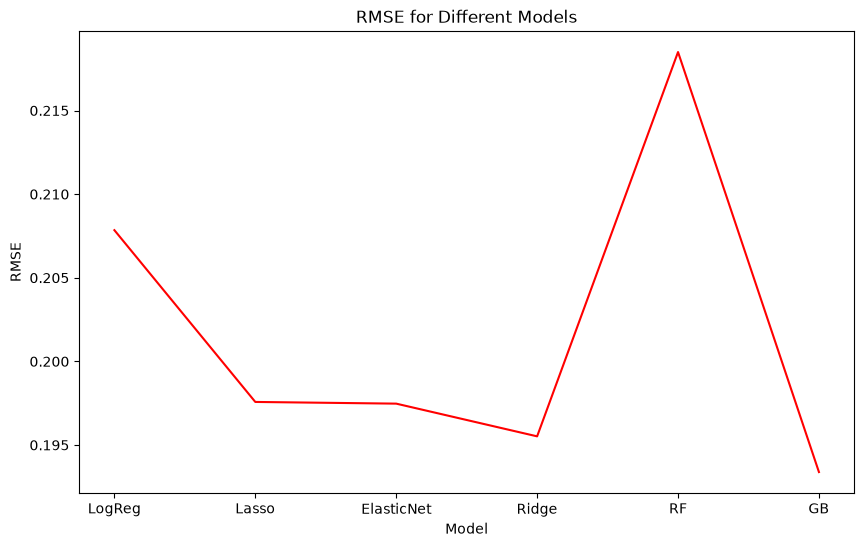

In [69]:
# Plot RMSE
plt.figure(figsize=(10, 6))
plt.plot(models_abbr, metrics_df['RMSE'], color='red')
plt.xlabel('Model')
plt.ylabel('RMSE')
plt.title('RMSE for Different Models')
plt.show()

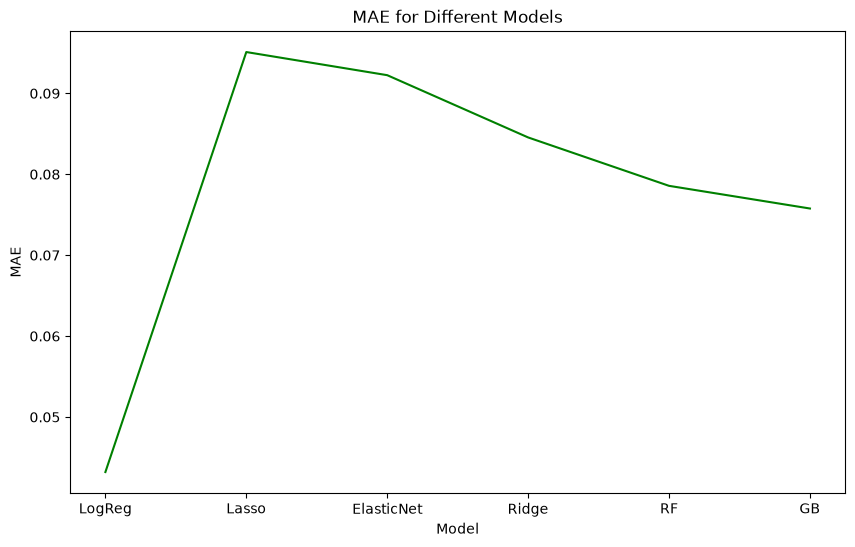

In [70]:
# Plot MAE
plt.figure(figsize=(10, 6))
plt.plot(models_abbr, metrics_df['MAE'], color='green')
plt.xlabel('Model')
plt.ylabel('MAE')
plt.title('MAE for Different Models')
plt.show()

We see from the above table and plots that, based on higher $R^2$ and Adjusted $R^2$, as well as lower RMSE, the Gradient Boosting Regression model works the best in predicting first-year enrollments. Although Logistic Regression has a lower MAE, Gradient Boosting Regression performs better in the other metrics. As a result, the model we will choose will be Gradient Boosting Regression.